In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("customer_behavior.csv")

print(df.head())
print(df.info())
print(df.isnull().sum())

   CustomerID  Gender Region  PurchaseAmount ProductCategory Churn  \
0        1001    Male  South          256.07         Fashion    No   
1        1002  Female  South             NaN     Electronics   Yes   
2        1003  Female   West         1194.41         Fashion    No   
3        1004  Female  South          413.06         Grocery    No   
4        1005    Male   West         1556.32         Fashion   Yes   

  CampaignGroup  
0             A  
1             B  
2             A  
3             A  
4             A  
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       5000 non-null   int64  
 1   Gender           4903 non-null   str    
 2   Region           4825 non-null   str    
 3   PurchaseAmount   4850 non-null   float64
 4   ProductCategory  4474 non-null   str    
 5   Churn            4735 non-null   str    
 6   Cam

In [3]:
mean_value = df["PurchaseAmount"].mean()
median_value = df["PurchaseAmount"].median()
mode_value = df["PurchaseAmount"].mode()

print("Mean:", mean_value)
print("Median:", median_value)
print("Mode:", mode_value.tolist())

Mean: 1003.9506701030928
Median: 998.0799999999999
Mode: [0.0]


Lower limit: -306.51000000000033
Upper limit: 2307.2300000000005
Number of outliers: 15
      CustomerID  PurchaseAmount
195         1196         2318.33
265         1266         2496.41
348         1349         2688.69
411         1412         2349.16
826         1827         2578.89
1358        2359         2384.19
2285        3286         2457.05
2557        3558         2316.19
2681        3682         2400.69
3326        4327         2357.41
3438        4439         2688.88
3564        4565         2643.88
4345        5346         2472.62
4693        5694         2484.75
4808        5809         2642.06


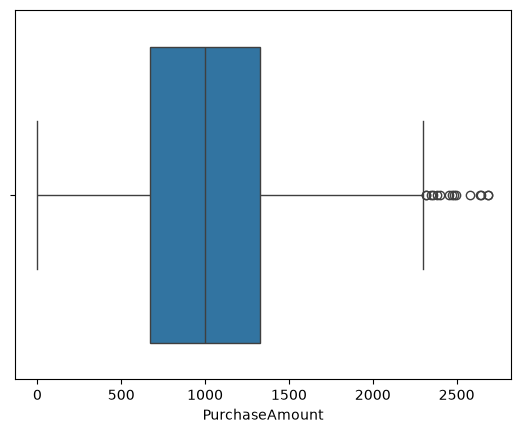

In [4]:
Q1 = df["PurchaseAmount"].quantile(0.25)
Q3 = df["PurchaseAmount"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["PurchaseAmount"] < lower_limit) |
    (df["PurchaseAmount"] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of outliers:", len(outliers))
print(outliers[["CustomerID", "PurchaseAmount"]])

sns.boxplot(x=df["PurchaseAmount"])
plt.show()

Skewness: 0.10609189374631554
Excess Kurtosis: -0.2615105545319705


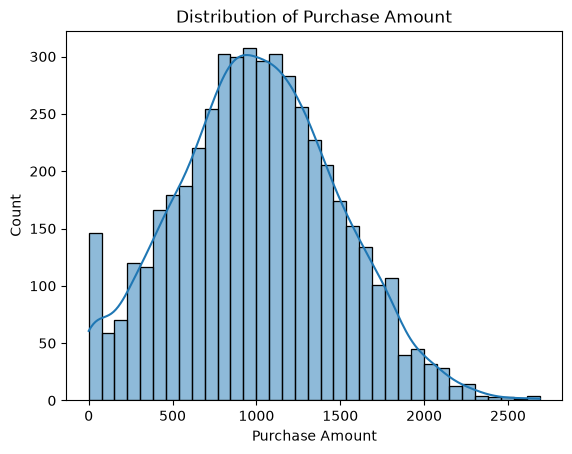

In [5]:
skewness = df["PurchaseAmount"].skew()
kurtosis = df["PurchaseAmount"].kurt()

print("Skewness:", skewness)
print("Excess Kurtosis:", kurtosis)

sns.histplot(df["PurchaseAmount"], kde=True)
plt.title("Distribution of Purchase Amount")
plt.xlabel("Purchase Amount")
plt.show()

In [6]:
male = df.loc[
    df["Gender"] == "Male", "PurchaseAmount"
].dropna()

female = df.loc[
    df["Gender"] == "Female", "PurchaseAmount"
].dropna()

print("Male average:", male.mean())
print("Female average:", female.mean())

t_stat, p_value = stats.ttest_ind(
    male, female, equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

Male average: 1019.1766093880973
Female average: 987.8720464135021
T-statistic: 2.234798912073049
P-value: 0.025476849797238164


In [7]:
contingency_table = pd.crosstab(
    df["ProductCategory"], df["Churn"]
)

print(contingency_table)

chi2, p_value, dof, expected = stats.chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)
print("Expected frequencies:\n", expected)

Churn             No  Yes
ProductCategory          
Electronics      785  541
Fashion          839  607
Grocery          855  604
Chi-square statistic: 0.3960436652673918
Degrees of freedom: 2
P-value: 0.8203519424988512
Expected frequencies:
 [[776.9212952  549.0787048 ]
 [847.23091468 598.76908532]
 [854.84779012 604.15220988]]


In [8]:
region_groups = [
    group["PurchaseAmount"].dropna().values
    for _, group in df.groupby("Region")
    if group["PurchaseAmount"].notna().any()
]

f_stat, p_value = stats.f_oneway(*region_groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

print(df.groupby("Region")["PurchaseAmount"].agg(
    ["count", "mean", "median", "std"]
))

F-statistic: 0.38966786354806704
P-value: 0.7604528027310101
        count         mean    median         std
Region                                          
East     1195  1009.946017  1006.290  490.355691
North    1167  1013.017952  1000.160  467.897373
South    1202   997.603877  1000.935  484.095616
West     1115   995.247327   985.160  485.801447


In [9]:
campaign_summary = df.groupby("CampaignGroup")[
    "PurchaseAmount"
].agg(["count", "mean", "median", "std"])

print(campaign_summary)

campaign_a = df.loc[
    df["CampaignGroup"] == "A", "PurchaseAmount"
].dropna()

campaign_b = df.loc[
    df["CampaignGroup"] == "B", "PurchaseAmount"
].dropna()

t_stat, p_value = stats.ttest_ind(
    campaign_a, campaign_b, equal_var=False
)

print("Campaign A average:", campaign_a.mean())
print("Campaign B average:", campaign_b.mean())
print("P-value:", p_value)

               count         mean    median         std
CampaignGroup                                          
A               2350  1011.945587  1010.155  480.160915
B               2318   994.339965   977.235  487.383742
Campaign A average: 1011.9455872340425
Campaign B average: 994.3399654874893
P-value: 0.21389858277292217
